# Measuring Hα SFRs with `carpenter` and comparing to DESI spectroscopy

This notebook walks through the full workflow for extracting photometric Hα
fluxes from Merian N708 narrow-band imaging using the `carpenter` package, and
validates them against spectroscopic Hα measurements from DESI DR1.

**Outline**
1. Load a sample of Merian–DESI matched galaxies
2. Estimate the continuum-subtracted Hα flux via `mbestimate_emission_line`
4. Apply corrections: Galactic extinction, [NII]/[SII] contamination,
   stellar absorption, aperture, and intrinsic dust
5. Convert to SFR (2012) and compare with the DESI spectroscopic value

The catalog used here is the Merian DR1 × DESI DR1 cross-match produced by
the Merian metallicity pipeline (Mintz et al. in prep).

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.table import Table
from astropy.cosmology import WMAP9 as cosmo
from scipy import stats

# carpenter: medium-band photometry utilities
from carpenter import emission, pixels, conventions, utils


CAT_PATH    = 'example_catalogs'


## Load the catalog

`example_merian_desi.fits` is a version of the Merian DR1 × DESI DR1 matched
catalog after quality cuts (redshift 0.064–0.094, DESI spectroscopic quality,
all Merian bands detected).
It contains both the Merian photometric columns and the FastSpecFit emission-line
measurements from DESI.


In [2]:
cat = Table.read(os.path.join(CAT_PATH, 'example_merian_desi.fits'))
print(f'Sample: {len(cat)} galaxies')
print(f'Redshift range:  {cat["Z"].min():.3f} – {cat["Z"].max():.3f}')
print(f'Stellar mass range: {np.nanmin(cat["LOGMSTAR_SAGA"]):.1f} – {np.nanmax(cat["LOGMSTAR_SAGA"]):.1f}  log M☉')


Sample: 6956 galaxies
Redshift range:  0.064 – 0.094
Stellar mass range: 8.0 – 11.2  log M☉


## Do continuum subtraction with carpenter

In [3]:
# ── Galactic extinction and adjacent-line corrections ─────────────────────────
N708_ge_corr = emission.compute_galactic_extinction(cat['coord_ra_merian'],
                                                    cat['coord_dec_merian'])[:, 2]
line_cor_desi = emission.correct_NIISII(cat['Z'], cat['LOGMSTAR_SAGA'], source='DESI')

# ── Photometric Hα from N708 narrowband (Merian) ─────────────────────────────
n708_fluxes, n708_luminosities, n708_eqws, n708_fcont, ha_cont = emission.mbestimate_emission_line(
    cat['n708_gaap1p0flux_merian'],
    cat['g_gaap1p0flux_apercorr_merian'],
    cat['r_gaap1p0flux_apercorr_merian'],
    cat['i_gaap1p0flux_apercorr_merian'],
    cat['z_gaap1p0flux_apercorr_merian'],
    cat['Z'],
    cat['n708_gaap1p0fluxerr_merian'],
    0., 0.,
    band='n708',
    apercorr=1.,
    ge_correction=N708_ge_corr,
    ex_correction=1,
    u_ex_correction=0.,
    ns_correction=1 / line_cor_desi,
    do_aperturecorrection=False,
    do_gecorrection=True,
    do_extinctioncorrection=False,
    do_linecorrection=True,
    specflux_unit=u.nJy,
    ctype='powerlaw',
    plawbands='riz',
    return_continuum_at_line_center=True,
)

# Absorption correction: constant 2 Å stellar absorption
EW_abs_cor = 2 * u.AA
flux_abs_cor = (EW_abs_cor
                * utils.fnu_to_flambda(6563 * (1 + cat['Z']) * u.AA, n708_fcont)
                .to(u.erg / u.s / u.cm**2 / u.AA))
lum_abs_cor = flux_abs_cor * n708_luminosities[0] / n708_fluxes[0]

# Rest-frame EW with absorption correction
n708_eqws = n708_eqws[0] / (1 + cat['Z']) + EW_abs_cor

# Aperture correction: cmodel / gaap
ap_ratio = cat['n708_cmodelflux_merian'] / cat['n708_gaap1p0flux_merian']
n708_fluxes_ap_cor = (n708_fluxes[0] + flux_abs_cor) * ap_ratio
ha_lum_ap_cor = (n708_luminosities[0] + lum_abs_cor) * ap_ratio

# Intrinsic dust correction
ha_lum_ap_cor *= cat['dust_corr']


# Convert to SFR following Kennicutt 2012
log_sfr_ha_mer = np.log10(ha_lum_ap_cor.value) - 41.27
log_ssfr_ha_mer = log_sfr_ha_mer - cat['LOGMSTAR_SAGA']


# Save vals
cat['ha_ew_mer']       = n708_eqws.value
cat['ha_flux_mer']     = n708_fluxes_ap_cor.value
cat['ha_lum_mer']      = ha_lum_ap_cor.to(u.Lsun).value
cat['log_sfr_ha_mer']  = log_sfr_ha_mer
cat['log_ssfr_ha_mer'] = log_ssfr_ha_mer


Loading precomputed Galactic extinction map...
Interpolated Galactic extinction values from map.


/var/folders/3y/_gc1bqxx1vq9klnm1fgr1z500000gn/T/ipykernel_84083/2693243134.py:52: RuntimeWarning: invalid value encountered in log10
  log_sfr_ha_mer = np.log10(ha_lum_ap_cor.value) - 41.27


## Save ha values from DESI spec

In [4]:
# ── Spectroscopic Hα SFR from DESI (HALPHA_FLUX) ─────────────────────────────
# Aperture correction from median of FLUX/FLUX_SYNTH across g, r, z bands
ap_cor = np.median(np.array([cat[f'FLUX_{b}'] / cat[f'FLUX_SYNTH_{b}']
                             for b in 'GRZ']), axis=0)
ha_lum_des = (cat['HALPHA_FLUX'] * ap_cor * 1e-17 * u.erg / u.cm**2 / u.s
              * 4 * np.pi * cosmo.luminosity_distance(cat['Z']).to(u.cm)**2)
ha_lum_des *= cat['dust_corr']

log_sfr_ha_des  = np.log10(ha_lum_des.value) - 41.27
log_ssfr_ha_des = log_sfr_ha_des - cat['LOGMSTAR_SAGA']

# Inf arises when HALPHA_FLUX <= 0; replace with nan
log_sfr_ha_des[np.isinf(log_sfr_ha_des)]   = np.nan
log_ssfr_ha_des[np.isinf(log_ssfr_ha_des)] = np.nan

cat['ha_lum_des']      = ha_lum_des.to(u.Lsun).value
cat['log_sfr_ha_des']  = log_sfr_ha_des
cat['log_ssfr_ha_des'] = log_ssfr_ha_des

/var/folders/3y/_gc1bqxx1vq9klnm1fgr1z500000gn/T/ipykernel_84083/3799446772.py:9: RuntimeWarning: divide by zero encountered in log10
  log_sfr_ha_des  = np.log10(ha_lum_des.value) - 41.27
/var/folders/3y/_gc1bqxx1vq9klnm1fgr1z500000gn/T/ipykernel_84083/3799446772.py:9: RuntimeWarning: invalid value encountered in log10
  log_sfr_ha_des  = np.log10(ha_lum_des.value) - 41.27


In [5]:
# Only star forming things
ha_ew_cut = (cat['ha_ew_mer'] > 10) & (cat['HALPHA_EW'] > 10)

<>:28: SyntaxWarning: invalid escape sequence '\s'
<>:28: SyntaxWarning: invalid escape sequence '\s'
/var/folders/3y/_gc1bqxx1vq9klnm1fgr1z500000gn/T/ipykernel_84083/2358437042.py:28: SyntaxWarning: invalid escape sequence '\s'
  a.text(0.07, 0.89, f"$\sigma=$ {np.nanstd(cat['log_sfr_ha_mer'][ha_ew_cut] - cat['log_sfr_ha_des'][ha_ew_cut]):.2f}", transform = a.transAxes, fontsize =15)


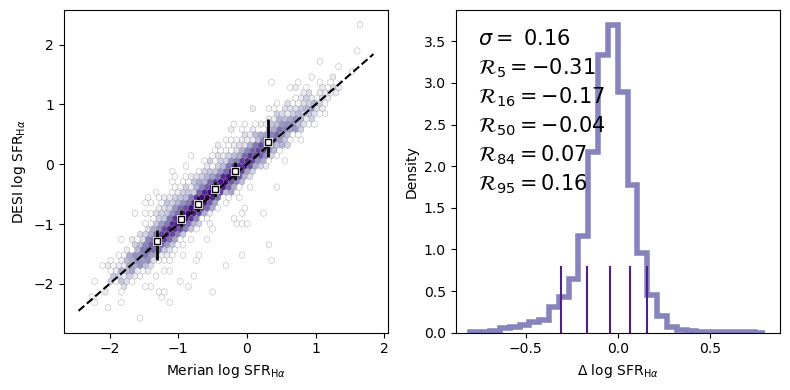

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(8,4))
a = ax[0]
a.hexbin(cat['log_sfr_ha_mer'][ha_ew_cut], cat['log_sfr_ha_des'][ha_ew_cut], gridsize=50, cmap='Purples', mincnt=1, alpha=1, bins='log', linewidths=0.2, edgecolors='grey')

x, y = cat['log_sfr_ha_mer'][ha_ew_cut], cat['log_sfr_ha_des'][ha_ew_cut]
bins = np.nanpercentile(x, np.linspace(0, 100, 7))
bin_centers = stats.binned_statistic(x, x, statistic='median', bins=bins)[0]
bin_medians = stats.binned_statistic(x, y, statistic=lambda x: np.nanpercentile(x, 50), bins=bins)[0]
bin_low = bin_medians - stats.binned_statistic(x, y, statistic=lambda x: np.nanpercentile(x, 16), bins=bins)[0]
bin_high = stats.binned_statistic(x, y, statistic=lambda x: np.nanpercentile(x, 84), bins=bins)[0] - bin_medians

a.errorbar(bin_centers, bin_medians, yerr=[bin_low, bin_high], fmt='s', color='w', linewidth=2, markersize=5, mfc = 'w', mew=2,)
a.errorbar(bin_centers, bin_medians, yerr=[bin_low, bin_high], fmt='s', color='k', linewidth=2, markersize=5, mfc = 'w', mew=1,)

a.plot(a.get_xlim(), a.get_xlim(), ls='--', color='k')
a.set_xlabel(r'Merian log SFR$_{\text{H}\alpha}$')
a.set_ylabel(r'DESI log SFR$_{\text{H}\alpha}$')

a = ax[1]
a.hist(cat['log_sfr_ha_mer'][ha_ew_cut] - cat['log_sfr_ha_des'][ha_ew_cut], linewidth = 4, color = plt.get_cmap('Purples')(0.6),
       bins=30, histtype='step', range = (-0.8, 0.8), density=True)

[a.vlines(x, 0, 0.8, ls='-', color= plt.get_cmap('Purples')(0.9)) for x in np.nanpercentile(cat['log_sfr_ha_mer'][ha_ew_cut] - cat['log_sfr_ha_des'][ha_ew_cut], [5, 16, 50, 84, 95])]

[a.text(0.07, 0.8 - 0.09*i, r'$\mathcal{R}_{' + f'{p}' + '}=' + f'{x:.2f}$', transform = a.transAxes, fontsize =15) for i, (x, p) 
 in enumerate(zip(np.nanpercentile(cat['log_sfr_ha_mer'][ha_ew_cut] - cat['log_sfr_ha_des'][ha_ew_cut], [5, 16, 50, 84, 95]), [5, 16, 50, 84, 95]))]

a.text(0.07, 0.89, f"$\sigma=$ {np.nanstd(cat['log_sfr_ha_mer'][ha_ew_cut] - cat['log_sfr_ha_des'][ha_ew_cut]):.2f}", transform = a.transAxes, fontsize =15)
a.set_xlabel(r'$\Delta$ log SFR$_{\text{H}\alpha}$')
a.set_ylabel('Density')
fig.tight_layout()